# Tire Shop - Exploratory Data Analysis

**Goal:** understand where a real tire, battery and rim shop in Egypt makes its revenue and profit, and when it sells,
before designing the Power BI dashboard.

> **Confidentiality:** this is real point-of-sale data from a family-owned shop. The shop is not named, customer names are
> removed, and **all money values are scaled by a secret factor and perturbed per product**. Percentages, counts, dates
> and patterns are real; absolute EGP amounts are not.

**Data** (cleaned by `cleaning/clean_data.py`, see `docs/data_dictionary.md`):

| Table | What it covers |
|---|---|
| `fact_item_sales` + `dim_product` | All-time totals per product (343 products) from the POS *item profit* report |
| `fact_invoices` + `dim_date` | 2,036 invoices, 1 Apr - 3 Nov 2026, with corrected dates |

> The two sources cover slightly different periods and cannot be joined (the item report has
> no dates or invoice numbers). Product questions use the item report; time questions use
> the invoices. All money is in (scaled) EGP.

**Questions**
1. Where does the profit come from? (category mix)
2. How concentrated is profit across products?
3. Tires: which sizes, price points, origins and brands earn the margin?
4. Which products were sold below cost?
5. Batteries, rims and services
6. When does the shop sell? (month, day, weekday, hour)
7. How big are the tickets?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter

DATA = Path('../data/clean')
CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)

# --- Palette (dataviz reference palette, validated for colour-vision deficiency) ---
SURFACE, INK, INK2, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#8a8984', '#e7e6e2'
CAT = {'Tire': '#2a78d6', 'Battery': '#eb6834', 'Rim': '#1baf7a', 'Service': '#eda100'}  # colour follows category everywhere
BLUE, GRAY, CRITICAL = '#2a78d6', '#c9c8c2', '#d03b3b'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'figure.dpi': 110,
})

def style(ax, grid='x'):
    ax.grid(axis='y' if grid == 'x' else 'x', visible=False)
    ax.grid(axis=grid, visible=True)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)
    ax.tick_params(length=0)

def save(fig, name):
    fig.savefig(CHARTS / f'{name}.png', dpi=150, bbox_inches='tight')

def egp(v):
    a = abs(v)
    if a >= 1e6: return f'{v/1e6:,.2f}M'
    if a >= 1e4: return f'{v/1e3:,.0f}K'
    if a >= 1e3: return f'{v/1e3:,.1f}K'
    return f'{v:,.0f}'
k_fmt = FuncFormatter(lambda v, _: egp(v))

prod = pd.read_csv(DATA / 'dim_product.csv')
sales = pd.read_csv(DATA / 'fact_item_sales.csv')
inv = pd.read_csv(DATA / 'fact_invoices.csv', parse_dates=['invoice_datetime', 'business_date'])
items = sales.merge(prod, on='product_id')

def summarize(df, by):
    g = df.groupby(by, observed=True).agg(products=('product_id', 'size'), units=('qty_sold', 'sum'),
                                          revenue=('revenue', 'sum'), profit=('profit', 'sum'))
    g['margin'] = g.profit / g.revenue
    g['revenue_share'] = g.revenue / items.revenue.sum()
    g['profit_share'] = g.profit / items.profit.sum()
    return g

pct = lambda s: s.map('{:.1%}'.format)

## 0. Headline numbers

In [2]:
days_open = inv.business_date.nunique()
kpi = pd.Series({
    'Products sold (all time)': f'{len(items):,}',
    'Units sold': f'{items.qty_sold.sum():,}',
    'Revenue (item report)': egp(items.revenue.sum()),
    'Profit (item report)': egp(items.profit.sum()),
    'Margin': f'{items.profit.sum() / items.revenue.sum():.1%}',
    'Invoices (1 Apr - 3 Nov)': f'{len(inv):,}',
    'Invoice revenue': egp(inv.net_amount.sum()),
    'Trading days': days_open,
    'Revenue per trading day': egp(inv.net_amount.sum() / days_open),
    'Average ticket': f'{inv.net_amount.mean():,.0f}',
    'Median ticket': f'{inv.net_amount.median():,.0f}',
    'Walk-in share of invoices': f'{(inv.customer_type == "Walk-in").mean():.1%}',
})
kpi.to_frame('value')

,value
Products sold (all time),343
Units sold,"3,189"
Revenue (item report),3.76M
Profit (item report),903K
Margin,24.0%
Invoices (1 Apr - 3 Nov),"2,036"
Invoice revenue,3.46M
Trading days,208
Revenue per trading day,17K
Average ticket,"1,698"


## 1. Where does the profit come from?

,products,units,revenue,profit,margin,revenue_share,profit_share
category,,,,,,,
Tire,273,1122,"2,285,925","266,675",11.7%,60.8%,29.5%
Battery,41,334,"691,785","92,035",13.3%,18.4%,10.2%
Rim,26,26,"276,645","36,040",13.0%,7.4%,4.0%
Service,2,1706,"507,575","507,575",100.0%,13.5%,56.2%


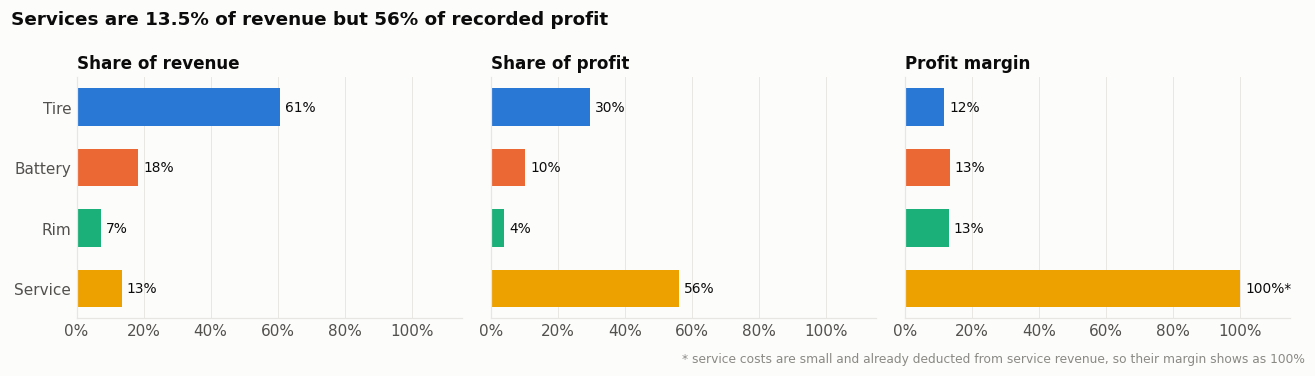

In [3]:
order = ['Tire', 'Battery', 'Rim', 'Service']
cat = summarize(items, 'category').reindex(order)
display(cat.assign(margin=pct(cat.margin), revenue_share=pct(cat.revenue_share), profit_share=pct(cat.profit_share))
          .style.format({'revenue': '{:,.0f}', 'profit': '{:,.0f}'}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, col, title in zip(axes, ['revenue_share', 'profit_share', 'margin'],
                          ['Share of revenue', 'Share of profit', 'Profit margin']):
    vals = cat[col]
    ax.barh(order[::-1], vals[::-1], color=[CAT[c] for c in order[::-1]], height=0.62)
    for y, (c, v) in enumerate(zip(order[::-1], vals[::-1])):
        star = '*' if (col == 'margin' and c == 'Service') else ''
        ax.text(v + 0.015, y, f'{v:.0%}{star}', va='center', color=INK, fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 1.15)
    style(ax)
fig.text(0.99, -0.02, '* service costs are small and already deducted from service revenue, so their margin shows as 100%', ha='right', fontsize=8, color=MUTED)
fig.suptitle(f"Services are {cat.loc['Service', 'revenue_share']:.1%} of revenue but "
             f"{cat.loc['Service', 'profit_share']:.0%} of recorded profit", x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '01_category_mix'); plt.show()

**Findings**
- **Tires are the volume business** (61% of revenue) but earn only **11.7%** margin;
  batteries 13.3%, rims 13.0%. Physical goods together earn about **12%**.
- **Services (welding, rim straightening) make 56% of recorded profit** from
  13.5% of revenue - 1,706 jobs. The owner confirmed their costs (gas, consumables)
  are **small and already deducted from the service revenue**, so this profit is real.

## 2. How concentrated is profit?

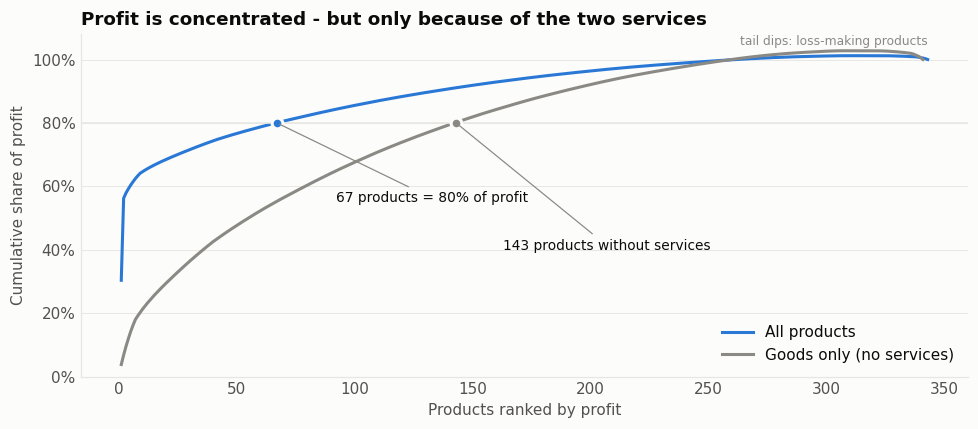

Products sold only once: 75 of 343
           products  profit
abc_class                  
A                67  722600
B               116  135100
C               160   44805


In [4]:
ranked = items.sort_values('profit', ascending=False).reset_index(drop=True)
ranked['cum_share'] = ranked.profit.cumsum() / ranked.profit.sum()
goods = items[items.category != 'Service'].sort_values('profit', ascending=False).reset_index(drop=True)
goods['cum_share'] = goods.profit.cumsum() / goods.profit.sum()
n80_all = int((ranked.cum_share < 0.8).sum() + 1)
n80_goods = int((goods.cum_share < 0.8).sum() + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(ranked) + 1), ranked.cum_share, color=BLUE, lw=2, label='All products')
ax.plot(np.arange(1, len(goods) + 1), goods.cum_share, color=MUTED, lw=2, label='Goods only (no services)')
ax.axhline(0.8, color=GRID, lw=1)
for n, y, c in [(n80_all, 0.8, BLUE), (n80_goods, 0.8, MUTED)]:
    ax.plot([n], [y], 'o', ms=7, color=c, mec=SURFACE, mew=2)
ax.annotate(f'{n80_all} products = 80% of profit', (n80_all, 0.8), (n80_all + 25, 0.55), color=INK, fontsize=9,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.annotate(f'{n80_goods} products without services', (n80_goods, 0.8), (n80_goods + 20, 0.4), color=INK, fontsize=9,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1.08)
ax.text(len(ranked), 1.045, 'tail dips: loss-making products', ha='right', fontsize=8, color=MUTED)
ax.set_xlabel('Products ranked by profit'); ax.set_ylabel('Cumulative share of profit')
ax.set_title('Profit is concentrated - but only because of the two services')
ax.legend(loc='lower right'); style(ax, 'y')
fig.tight_layout(); save(fig, '02_profit_pareto'); plt.show()

print(f'Products sold only once: {(items.qty_sold == 1).sum()} of {len(items)}')
print(items.groupby('abc_class').agg(products=('product_id', 'size'), profit=('profit', 'sum')))

**Findings**
- With services, **67 products (20%) make 80 % of profit** (ABC class A). The curves end slightly
  above 100 % and dip because the loss-making products come last.
- Without services the curve is much flatter: **143 of 341 goods** are needed for 80 % of goods profit.
  No single tire carries the shop; profit is spread over a long range of sizes.
- **75 products sold only once** - a long tail that ties up stock.

## 3. Tires

### 3a. Margin by rim size

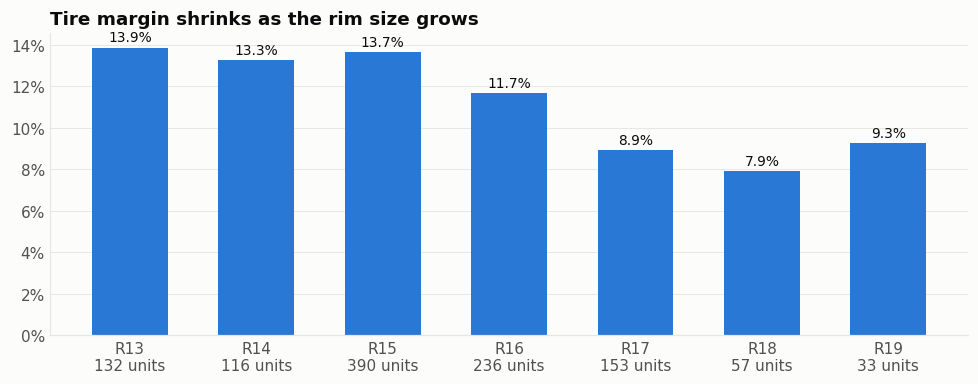

In [5]:
tires = items[items.category == 'Tire'].copy()
rim = summarize(tires, 'rim_diameter_in')
rim = rim[rim.units >= 10]                       # drop R12 / R20 (5 units)
labels = [f'R{int(r)}\n{u} units' for r, u in zip(rim.index, rim.units)]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(labels, rim.margin, color=CAT['Tire'], width=0.6)
for x, v in enumerate(rim.margin):
    ax.text(x, v + 0.003, f'{v:.1%}', ha='center', fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title('Tire margin shrinks as the rim size grows'); style(ax, 'y')
fig.tight_layout(); save(fig, '03_tire_margin_by_rim'); plt.show()

### 3b. Margin vs selling price

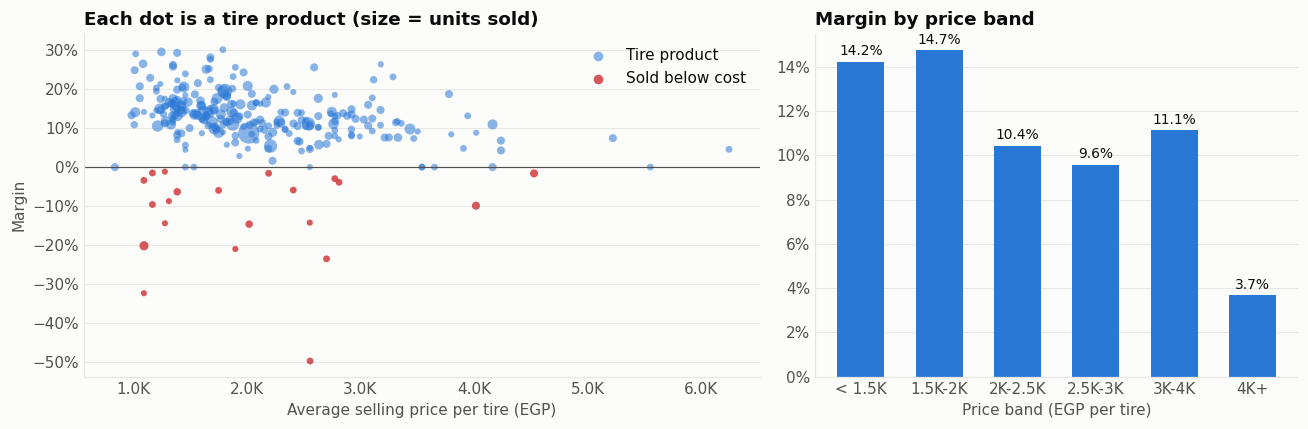

,products,units,revenue,profit,margin
price_band,,,,,
< 1.5K,78,293,380095,54130,14.2%
1.5K-2K,69,350,611090,90080,14.7%
2K-2.5K,49,224,488010,50925,10.4%
2.5K-3K,40,138,373755,35745,9.6%
3K-4K,27,80,266420,29670,11.1%
4K+,10,37,166555,6125,3.7%


In [6]:
band = summarize(tires, ['price_band_order', 'price_band']).droplevel(0)   # bands from the cleaning step

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.4, 1]})
ok, loss = tires[~tires.is_loss], tires[tires.is_loss]
a1.scatter(ok.unit_price, ok.margin_pct, s=12 + ok.qty_sold * 4, color=BLUE, alpha=0.55, lw=0, label='Tire product')
a1.scatter(loss.unit_price, loss.margin_pct, s=12 + loss.qty_sold * 4, color=CRITICAL, alpha=0.85, lw=0, label='Sold below cost')
a1.axhline(0, color=INK2, lw=0.8)
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); a1.xaxis.set_major_formatter(k_fmt)
a1.set_xlabel('Average selling price per tire (EGP)'); a1.set_ylabel('Margin')
a1.set_title('Each dot is a tire product (size = units sold)'); style(a1, 'y')
leg = a1.legend(loc='upper right')
for h in leg.legend_handles: h.set_sizes([40])

a2.bar(band.index.astype(str), band.margin, color=CAT['Tire'], width=0.6)
for x, v in enumerate(band.margin):
    a2.text(x, v + 0.003, f'{v:.1%}', ha='center', fontsize=9)
a2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); a2.set_xlabel('Price band (EGP per tire)')
a2.set_title('Margin by price band'); style(a2, 'y')
fig.tight_layout(); save(fig, '04_tire_price_vs_margin'); plt.show()
band.assign(margin=pct(band.margin))[['products', 'units', 'revenue', 'profit', 'margin']]

**Findings**
- The best-earning volume price band is **1.5K-2K EGP per tire: 14.7% margin** on 350 tires;
  the most expensive band (4K+) earns only **3.7%**.
- By size, **R13-R15 earn 13%-14%**,
  while **R17 and larger earn only 8.7%** - big tires bring revenue but little profit per pound sold.
- Margins are very scattered at every price, which points to **case-by-case pricing** rather than a fixed markup.

### 3c. Country of origin and brand

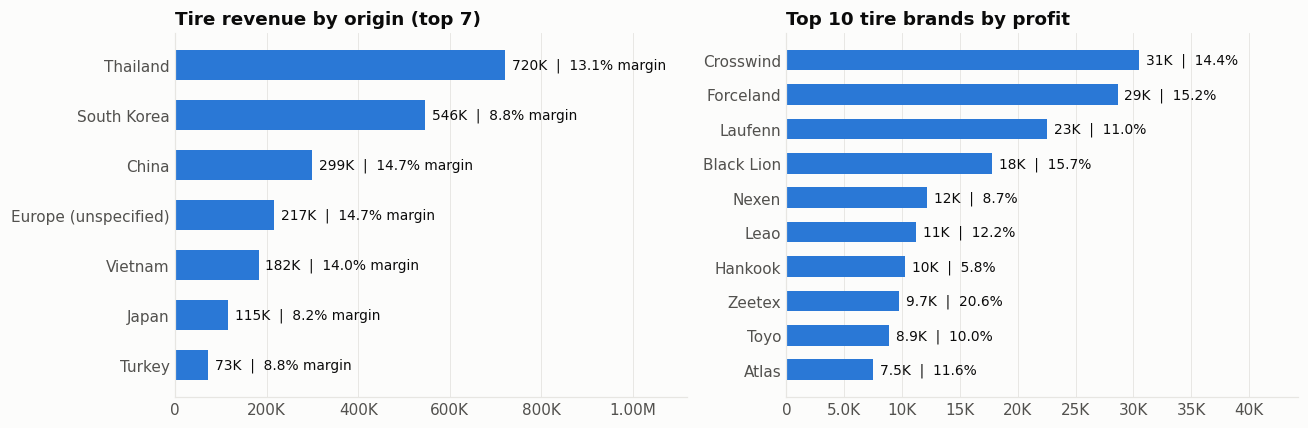

In [7]:
origin = summarize(tires, 'origin_country').sort_values('revenue', ascending=False)
top = origin.head(7)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.barh(top.index[::-1], top.revenue[::-1], color=CAT['Tire'], height=0.6)
for y, (r, m) in enumerate(zip(top.revenue[::-1], top.margin[::-1])):
    a1.text(r + 15000, y, f'{egp(r)}  |  {m:.1%} margin', va='center', fontsize=9)
a1.xaxis.set_major_formatter(k_fmt); a1.set_xlim(0, top.revenue.max() * 1.55)
a1.set_title('Tire revenue by origin (top 7)'); style(a1)

brand = summarize(tires, 'brand').sort_values('profit', ascending=False).head(10)
a2.barh(brand.index[::-1], brand.profit[::-1], color=CAT['Tire'], height=0.6)
for y, (p, m) in enumerate(zip(brand.profit[::-1], brand.margin[::-1])):
    a2.text(p + 600, y, f'{egp(p)}  |  {m:.1%}', va='center', fontsize=9)
a2.xaxis.set_major_formatter(k_fmt); a2.set_xlim(0, brand.profit.max() * 1.45)
a2.set_title('Top 10 tire brands by profit'); style(a2)
fig.tight_layout(); save(fig, '05_tire_origin_brand'); plt.show()

In [8]:
size = summarize(tires, 'tire_size').sort_values('units', ascending=False).head(10)
size.assign(margin=pct(size.margin), revenue_share=pct(size.revenue_share))[['products', 'units', 'revenue', 'profit', 'margin']]

,products,units,revenue,profit,margin
tire_size,,,,,
205/55 R16,16,140,261080,30030,11.5%
185/65 R15,21,123,216870,32765,15.1%
175/70 R13,18,92,117860,19435,16.5%
195/60 R15,16,80,142300,16625,11.7%
195/65 R15,14,63,111140,16975,15.3%
185/65 R14,10,47,70560,10435,14.8%
195/50 R15,7,35,54710,8170,14.9%
225/60 R17,9,34,97520,6910,7.1%
215/50 R17,7,33,87840,10500,12.0%


**Findings**
- **Thailand is the biggest source** (720K revenue, 13.1% margin).
  **South Korea is second (546K) but earns only 8.8%**;
  Hankook in particular earns **5.8%**. Japanese and Turkish tires are also below 9 %.
- **Chinese, Vietnamese and European (Crosswind) tires earn 14%-15%**.
- **Crosswind, Forceland and Laufenn** are the top profit brands; **Black Lion (15.7%)
  and Zeetex (20.6%)** have the best margins among brands with real volume.
- The top sizes are the common city-car sizes: **205/55 R16 (140 units), 185/65 R15 (123 units), 175/70 R13 (92 units)**.
  The same size is stocked in up to **21 different brands/origins**, which explains the long tail.

## 4. Products sold below cost

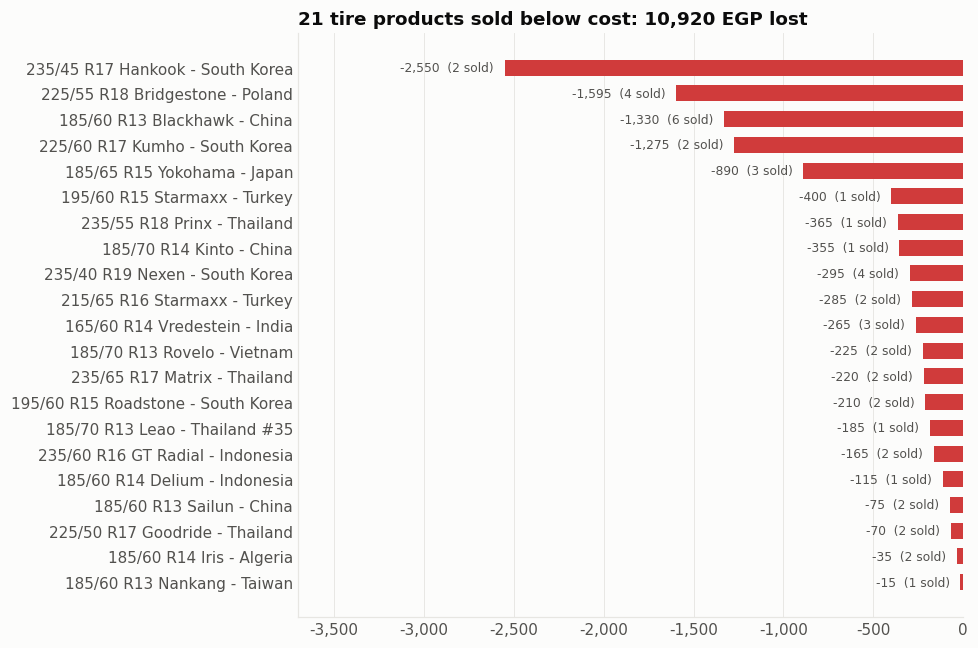

,product_name_en,qty_sold,unit_price,unit_cost,profit
226,235/45 R17 Hankook - South Korea,2,2557.50,3832.50,-2550
281,225/55 R18 Bridgestone - Poland,4,4017.50,4416.25,-1595
4,185/60 R13 Blackhawk - China,6,1095.83,1317.50,-1330
257,225/60 R17 Kumho - South Korea,2,2702.50,3340.00,-1275
134,185/65 R15 Yokohama - Japan,3,2021.67,2318.33,-890
105,195/60 R15 Starmaxx - Turkey,1,1900.00,2300.00,-400
282,235/55 R18 Prinx - Thailand,1,2555.00,2920.00,-365
70,185/70 R14 Kinto - China,1,1095.00,1450.00,-355
289,235/40 R19 Nexen - South Korea,4,4528.75,4602.50,-295
215,215/65 R16 Starmaxx - Turkey,2,2410.00,2552.50,-285


In [9]:
loss = items[items.is_loss].sort_values('profit')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(loss.product_name_en[::-1], loss.profit[::-1], color=CRITICAL, height=0.62)
for y, (p, q) in enumerate(zip(loss.profit[::-1], loss.qty_sold[::-1])):
    ax.text(p - 60, y, f'{p:,.0f}  ({q} sold)', va='center', ha='right', fontsize=8, color=INK2)
ax.set_xlim(loss.profit.min() * 1.45, 0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title(f'{len(loss)} tire products sold below cost: {-loss.profit.sum():,.0f} EGP lost'); style(ax)
fig.tight_layout(); save(fig, '06_loss_products'); plt.show()
loss[['product_name_en', 'qty_sold', 'unit_price', 'unit_cost', 'profit']]

**Findings**
- **21 products (all tires) lost 10,920 EGP** on 102K of sales - small in total, but each one is a pricing question.
- The worst cases are big or premium tires: **235/45 R17 Hankook sold at 2,558 vs 3,832 cost**,
  225/55 R18 Bridgestone, 225/60 R17 Kumho.
- **How cost is measured matters.** The POS uses the **last purchase price** as cost, and the owner confirmed some tires were
  knowingly sold below cost (clearance, matching a competitor, a loyal customer). So a "loss" can mean two different things:
  1. **A real below-cost sale** - the tire was sold for less than it was bought for.
  2. **A replacement-cost effect** - the tire was bought earlier at a lower price, the next purchase was more expensive, and the
     report values the old stock at the new price. The sale may have been profitable against what was actually paid.
- Grouping by how far below cost they sold helps separate the two:

| Gap below cost | Products | Loss (EGP) | Likely meaning |
|---|---|---|---|
| Small (< 5 %) | 7 | 875 | Rounding / small discount to close the sale |
| Medium (5-15 %) | 9 | 4,135 | Deliberate discount or price increase not passed on |
| Large (> 15 %) | 5 | 5,910 | Supplier price jump after the sale, or a wrong purchase price - **check purchase history** |

- With prices rising, **last-purchase-price cost makes every margin look lower than what was actually earned** on older stock.
  The margins here are margins **at replacement cost** - right for pricing the next sale, conservative for past profit.

## 5. Batteries, rims and services

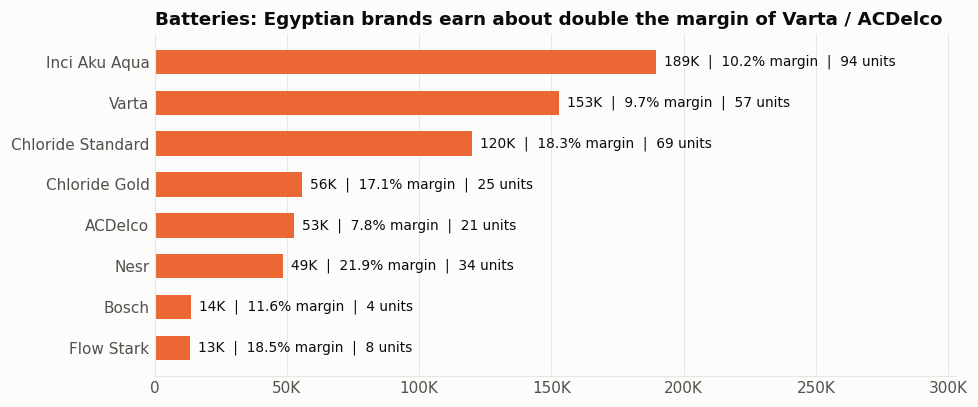

TD-70 share of battery units: 75%


,products,units,revenue,margin
battery_model,,,,
TD-70,10,251,510365,12.6%
NS-60,5,17,32540,13.9%
NS-40,2,17,21070,21.1%
DIN-74,6,12,40650,10.3%
N-90,3,8,20390,16.8%


In [10]:
bat = items[items.category == 'Battery']
line = summarize(bat, 'product_line').sort_values('revenue', ascending=False).head(8)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(line.index[::-1], line.revenue[::-1], color=CAT['Battery'], height=0.6)
for y, (r, m, u) in enumerate(zip(line.revenue[::-1], line.margin[::-1], line.units[::-1])):
    ax.text(r + 3000, y, f'{egp(r)}  |  {m:.1%} margin  |  {u} units', va='center', fontsize=9)
ax.xaxis.set_major_formatter(k_fmt); ax.set_xlim(0, line.revenue.max() * 1.6)
ax.set_title('Batteries: Egyptian brands earn about double the margin of Varta / ACDelco'); style(ax)
fig.tight_layout(); save(fig, '07_battery_lines'); plt.show()

model = summarize(bat, 'battery_model').sort_values('units', ascending=False).head(5)
print(f"TD-70 share of battery units: {model.loc['TD-70', 'units'] / bat.qty_sold.sum():.0%}")
model.assign(margin=pct(model.margin))[['products', 'units', 'revenue', 'margin']]

In [11]:
rims = items[items.category == 'Rim']
print(f'Rims: {len(rims)} products, {rims.qty_sold.sum()} units (each sold once), '
      f'{egp(rims.revenue.sum())} revenue, {rims.profit.sum() / rims.revenue.sum():.1%} margin')

svc = items[items.category == 'Service'][['product_name_en', 'qty_sold', 'revenue', 'profit', 'unit_price']]
svc.rename(columns={'qty_sold': 'jobs', 'unit_price': 'avg price per job'})

Rims: 26 products, 26 units (each sold once), 277K revenue, 13.0% margin


,product_name_en,jobs,revenue,profit,avg price per job
321,Rim Straightening & Welding,527,274075,274075,520.07
322,Welding,1179,233500,233500,198.05


**Findings**
- **Batteries:** TD-70 is **75% of battery units**. Egyptian lines (**Chloride 17%-18%,
  Nesr 22%**) earn about double the margin of **Varta (9.7%) and ACDelco
  (7.8%)**; Inci Aku (Turkey) is the volume leader at 10%.
- **Rims:** 26 different rims, each sold once - a low-volume, made-to-order line (13% margin).
- **Services:** 1,179 welding jobs (avg 198 EGP) and 527 rim-straightening jobs
  (avg 520 EGP). Their small costs are already netted out, so **508K EGP of profit from
  1,706 jobs** - about 298 EGP per job, against ~238 EGP per tire sold.
  **They are the shop's most valuable line** and the main reason customers walk in.

## 6. When does the shop sell?

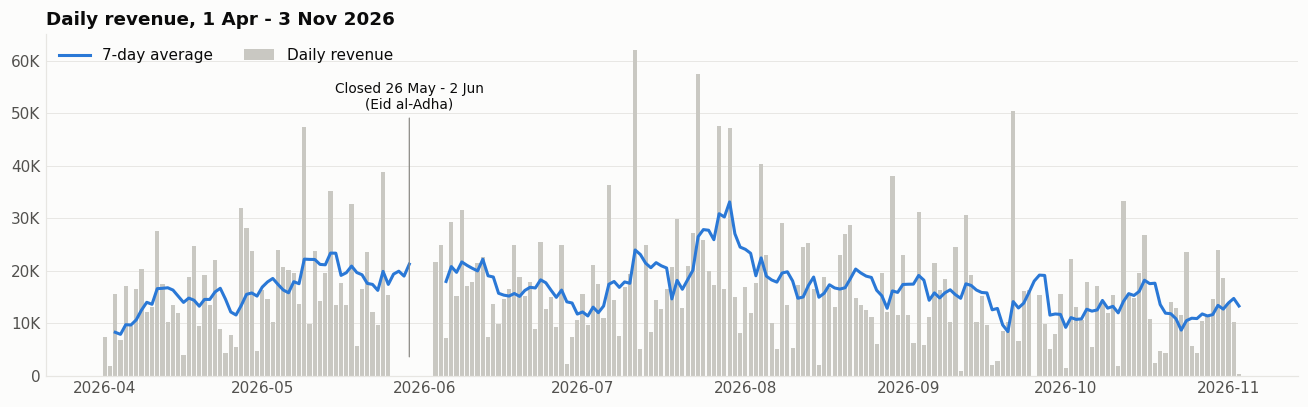

Days with no sales: 26 May, 27 May, 28 May, 29 May, 30 May, 31 May, 01 Jun, 02 Jun, 25 Sep


In [12]:
daily = inv.groupby('business_date').agg(invoices=('invoice_no', 'size'), revenue=('net_amount', 'sum'))
cal = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
roll = cal.revenue.where(cal.invoices > 0).rolling(7, min_periods=3).mean()   # closed days = gap, not zero

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(cal.index, cal.revenue, color=GRAY, width=0.8, label='Daily revenue')
ax.plot(roll.index, roll, color=BLUE, lw=2, label='7-day average')
closed = cal[cal.invoices == 0].index
ax.annotate('Closed 26 May - 2 Jun\n(Eid al-Adha)', (pd.Timestamp('2026-05-29'), 3000), (pd.Timestamp('2026-05-29'), cal.revenue.max() * 0.82),
            fontsize=9, ha='center', arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.yaxis.set_major_formatter(k_fmt); ax.set_title('Daily revenue, 1 Apr - 3 Nov 2026')
ax.legend(loc='upper left', ncol=2); style(ax, 'y')
fig.tight_layout(); save(fig, '08_daily_revenue'); plt.show()
print('Days with no sales:', ', '.join(d.strftime('%d %b') for d in closed))

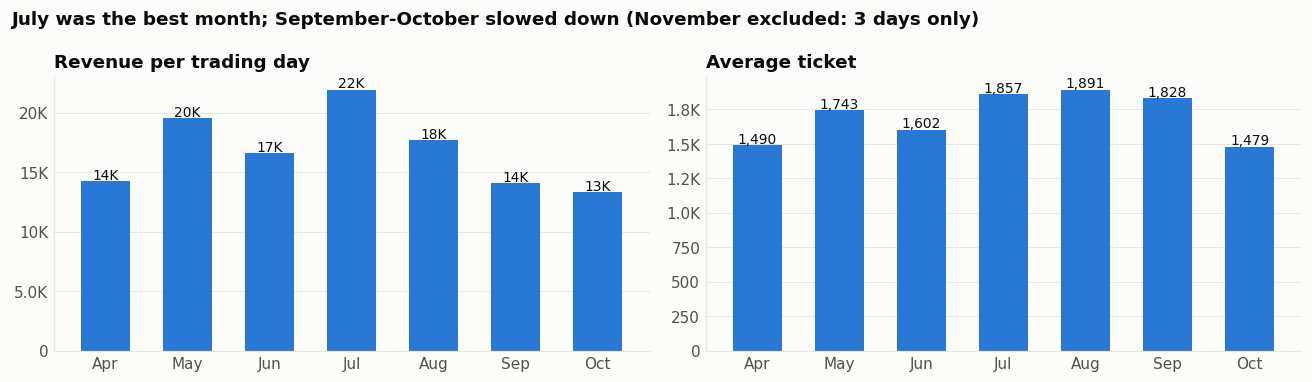

,invoices,revenue,days,revenue_per_day,invoices_per_day,avg_ticket
business_date,,,,,,
2026-04,287,427505,30,14250.0,10.0,1490.0
2026-05,280,487940,25,19518.0,11.0,1743.0
2026-06,290,464585,28,16592.0,10.0,1602.0
2026-07,366,679695,31,21926.0,12.0,1857.0
2026-08,290,548490,31,17693.0,9.0,1891.0
2026-09,224,409580,29,14123.0,8.0,1828.0
2026-10,280,414190,31,13361.0,9.0,1479.0


In [13]:
full_months = inv[inv.business_date < '2026-11-01']
m = full_months.groupby(full_months.business_date.dt.to_period('M')).agg(
    invoices=('invoice_no', 'size'), revenue=('net_amount', 'sum'), days=('business_date', 'nunique'))
m['revenue_per_day'] = m.revenue / m.days
m['invoices_per_day'] = m.invoices / m.days
m['avg_ticket'] = m.revenue / m.invoices
labels = m.index.strftime('%b')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.bar(labels, m.revenue_per_day, color=BLUE, width=0.6)
a2.bar(labels, m.avg_ticket, color=BLUE, width=0.6)
for ax, col, title in [(a1, 'revenue_per_day', 'Revenue per trading day'), (a2, 'avg_ticket', 'Average ticket')]:
    for x, v in enumerate(m[col]):
        ax.text(x, v * 1.01, egp(v) if v >= 1e4 else f'{v:,.0f}', ha='center', fontsize=9)
    ax.yaxis.set_major_formatter(k_fmt); ax.set_title(title); style(ax, 'y')
fig.suptitle('July was the best month; September-October slowed down (November excluded: 3 days only)',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '09_monthly'); plt.show()
m.round(0)

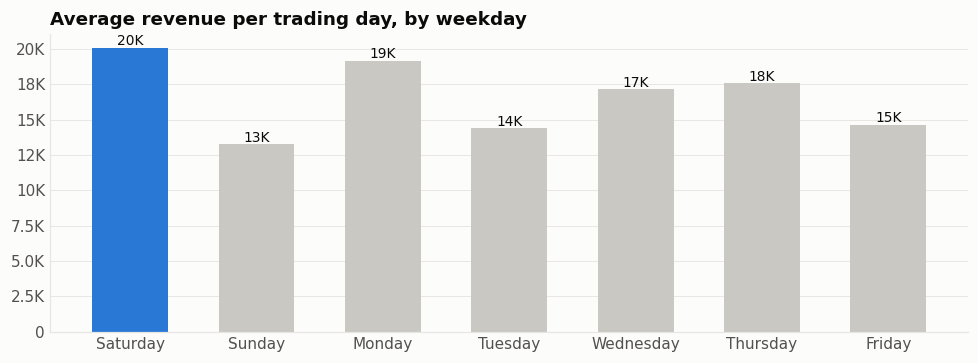

,days,avg_revenue,avg_invoices
weekday,,,
Saturday,30,20033.0,11.9
Sunday,30,13280.5,8.9
Monday,30,19125.0,10.1
Tuesday,29,14395.2,9.3
Wednesday,30,17146.7,10.7
Thursday,30,17555.8,9.4
Friday,29,14645.3,8.2


In [14]:
wd_order = ['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
wd = daily.assign(weekday=daily.index.day_name()).groupby('weekday').agg(
    days=('revenue', 'size'), avg_revenue=('revenue', 'mean'), avg_invoices=('invoices', 'mean')).reindex(wd_order)
best = wd.avg_revenue.idxmax()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(wd.index, wd.avg_revenue, color=[BLUE if d == best else GRAY for d in wd.index], width=0.6)
for x, v in enumerate(wd.avg_revenue):
    ax.text(x, v * 1.01, egp(v), ha='center', fontsize=9)
ax.yaxis.set_major_formatter(k_fmt); ax.set_title('Average revenue per trading day, by weekday'); style(ax, 'y')
fig.tight_layout(); save(fig, '10_weekday'); plt.show()
wd.round(1)

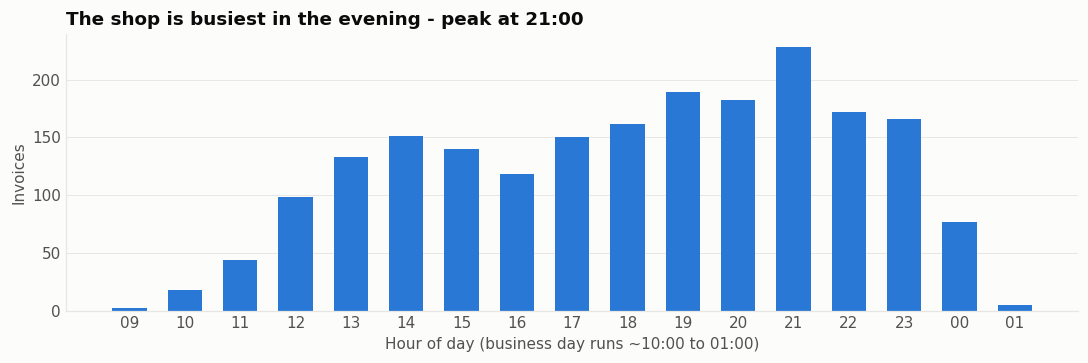

18:00-23:59: 54% of invoices, 56% of revenue
After midnight: 82 invoices, 182,930 EGP (avg ticket 2,231)


In [15]:
hour_order = list(range(9, 24)) + [0, 1]
timed = inv[~inv.is_time_estimated]
hourly = timed.groupby('invoice_hour').agg(invoices=('invoice_no', 'size'), revenue=('net_amount', 'sum')).reindex(hour_order, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar([f'{h:02d}' for h in hour_order], hourly.invoices, color=BLUE, width=0.62)
ax.set_xlabel('Hour of day (business day runs ~10:00 to 01:00)'); ax.set_ylabel('Invoices')
ax.set_title('The shop is busiest in the evening - peak at 21:00'); style(ax, 'y')
fig.tight_layout(); save(fig, '11_hourly'); plt.show()

evening = hourly.loc[[18, 19, 20, 21, 22, 23]].sum() / hourly.sum()
late = inv[inv.is_after_midnight]
print(f'18:00-23:59: {evening.invoices:.0%} of invoices, {evening.revenue:.0%} of revenue')
print(f'After midnight: {len(late)} invoices, {late.net_amount.sum():,.0f} EGP (avg ticket {late.net_amount.mean():,.0f})')

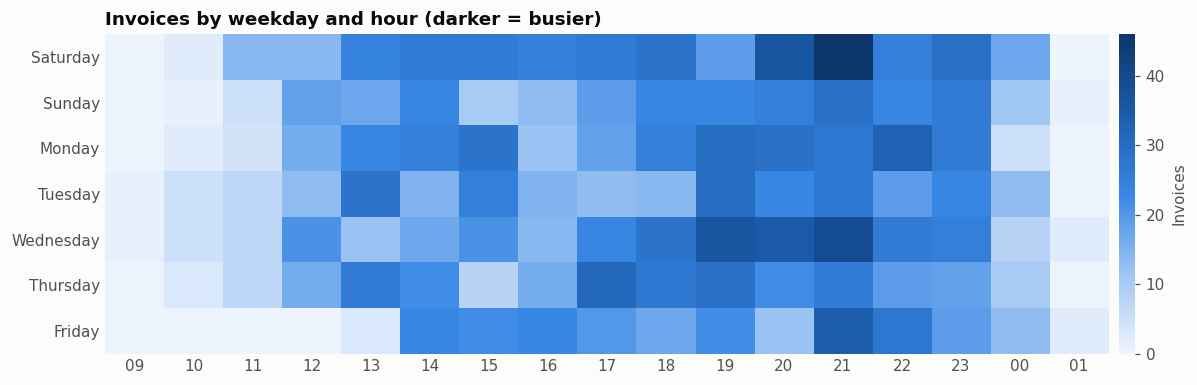

In [16]:
timed = timed.assign(weekday=timed.business_date.dt.day_name())
heat = timed.pivot_table(index='weekday', columns='invoice_hour', values='invoice_no', aggfunc='size', fill_value=0)
heat = heat.reindex(index=wd_order, columns=[h for h in hour_order if h in heat.columns], fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat.values, cmap=SEQ, aspect='auto')
ax.set_xticks(range(heat.shape[1]), [f'{h:02d}' for h in heat.columns])
ax.set_yticks(range(7), wd_order); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label('Invoices', color=INK2); cb.outline.set_visible(False)
ax.set_title('Invoices by weekday and hour (darker = busier)')
fig.tight_layout(); save(fig, '12_weekday_hour_heatmap'); plt.show()

**Findings**
- **208 trading days**, about **17K EGP and 10 invoices per day**. The shop closed for
  **Eid al-Adha (26 May - 2 Jun)** and one Friday.
- **July was the best month** (22K per day); **September and October slowed to
  ~14K and 13K per day**.
- **Saturday (20K) and Monday (19K) are the strongest
  days; Sunday (13K) is the weakest.**
- **It is an evening business:** 58% of invoices and 61% of revenue come after 18:00 (including
  after midnight), peaking at **21:00**. **82 after-midnight invoices brought 183K EGP**
  (average ticket ~2,231) - late-night tire sales, not just repairs.

## 7. Ticket size

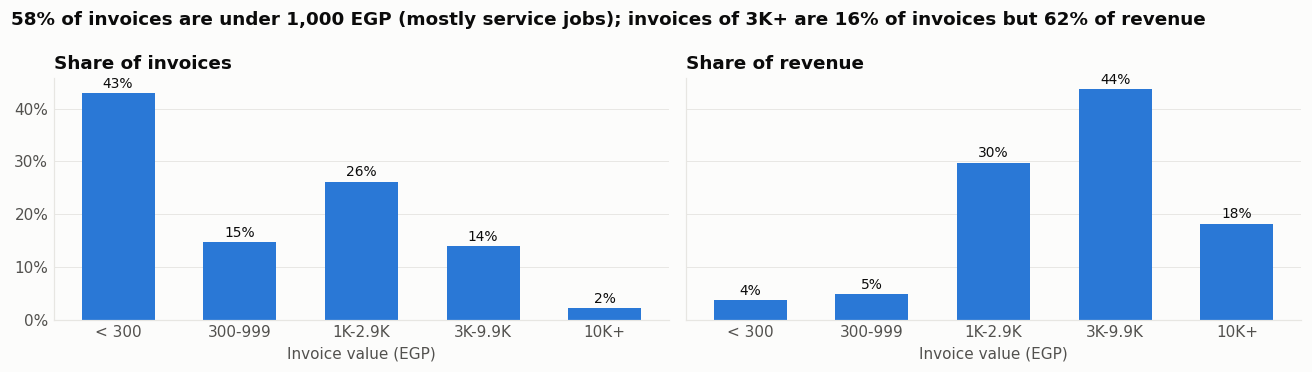

Most common invoice amounts: {90: 113, 75: 108, 145: 102, 60: 75, 220: 71, 110: 64}
Named (non walk-in) customers: 33 invoices; repeat named customers: 2


,invoices,revenue,share_invoices,share_revenue
ticket_band,,,,
< 300,875,124795,43.0%,3.6%
300-999,300,165585,14.7%,4.8%
1K-2.9K,532,1028375,26.1%,29.8%
3K-9.9K,284,1509230,13.9%,43.7%
10K+,45,628420,2.2%,18.2%


In [17]:
tb = inv.groupby(['ticket_band_order', 'ticket_band']).agg(invoices=('invoice_no', 'size'), revenue=('net_amount', 'sum')).droplevel(0)
tb['share_invoices'] = tb.invoices / tb.invoices.sum()
tb['share_revenue'] = tb.revenue / tb.revenue.sum()
labels = list(tb.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, col, title in zip(axes, ['share_invoices', 'share_revenue'], ['Share of invoices', 'Share of revenue']):
    ax.bar(labels, tb[col], color=BLUE, width=0.6)
    for x, v in enumerate(tb[col]):
        ax.text(x, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_title(title)
    ax.set_xlabel('Invoice value (EGP)'); style(ax, 'y')
fig.suptitle(f"{tb.share_invoices.iloc[:2].sum():.0%} of invoices are under 1,000 EGP (mostly service jobs); "
             f"invoices of 3K+ are {tb.share_invoices.iloc[3:].sum():.0%} of invoices but "
             f"{tb.share_revenue.iloc[3:].sum():.0%} of revenue",
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '13_ticket_size'); plt.show()

print('Most common invoice amounts:', inv.net_amount.value_counts().head(6).to_dict())
print(f"Named (non walk-in) customers: {(inv.customer_type != 'Walk-in').sum()} invoices; repeat named customers: "
      f"{(inv[inv.customer_type != 'Walk-in'].customer_id.value_counts() > 1).sum()}")
tb.assign(share_invoices=pct(tb.share_invoices), share_revenue=pct(tb.share_revenue))

**Findings**
- **58% of invoices are under 1,000 EGP but bring only 8% of revenue.** These small tickets match
  welding jobs, so they are mostly **service visits**.
- **Invoices of 3,000 EGP and more are 16% of invoices but 62% of revenue.**
- **98% of invoices are walk-in cash**, so there is no customer history - repeat-customer analysis is impossible today.

## Summary of findings

| # | Finding | Evidence |
|---|---|---|
| 1 | **Services are the profit engine** - 56% of recorded profit from 13.5% of revenue, and most of the traffic | Sections 1, 5, 7 |
| 2 | **Goods earn thin margins** - tires 11.7%, batteries 13.3%, rims 13.0% | Section 1 |
| 3 | **Bigger and pricier tires earn less** - R17+ tires earn 8.7%; the 4K+ price band only 3.7% | Section 3 |
| 4 | **Korean, Japanese and Turkish tires sell well but at < 9 % margin**; Chinese, Vietnamese and European tires earn ~14-15 % | Section 3 |
| 5 | **21 tires were sold below their last purchase price**; 5 by more than 15 %, mostly large premium sizes | Section 4 |
| 6 | **Egyptian batteries earn ~2x the margin of Varta / ACDelco**; TD-70 is 75% of units | Section 5 |
| 7 | **Long tail** - 343 products, 75 sold once; one size is stocked in up to 21 brands | Sections 2, 3 |
| 8 | **Evening business** - 58% of invoices after 18:00, peak 21:00 | Section 6 |
| 9 | **July peak, Sep-Oct slowdown**; Saturday and Monday strongest, Sunday weakest | Section 6 |
| 10 | **No customer data** - 98% walk-in | Section 7 |

### Recommendations
1. **Make below-cost sales a decision, not an accident:** a minimum-margin warning in the POS, and update selling prices as soon
   as a more expensive purchase is entered - with last-purchase-price costing, a stale price list turns into losses.
2. **Re-price large sizes and Korean brands**, or steer customers toward the higher-margin origins in the same size.
3. **Promote Egyptian battery lines** (Chloride, Nesr) where the customer has no brand preference.
4. **Grow the service line** - offer a tire or battery check with every welding / straightening job.
5. **Capture customer phone numbers** to enable repeat-customer analysis and reminders.
6. **Staff for the evening peak** (19:00-23:00); mornings before 12:00 bring only 3% of invoices.